# Indian Tech Jobs 

## 1. Project Overview

This project analyzes the Indian Tech Jobs 2026 dataset to understand hiring trends, job roles, salary patterns, required skills, experience levels, hiring locations, and work arrangements in the technology job market.

Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn are used to explore the dataset, perform analysis, and create visualizations.

## 2. Project Objectives

- Analyze the overall technology job market.
- Identify the most frequently listed job titles and hiring companies.
- Examine salary patterns across job roles and experience levels.
- Identify frequently mentioned skills in job descriptions.
- Understand hiring trends across cities and work modes.
- Explore fresher-friendly opportunities.
- Generate business insights that can support job seekers and career planning.

## 3. Tools and Technologies

- **Python:** Data analysis and exploration.
- **Pandas:** Data manipulation and aggregation.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualization.
- **Jupyter Notebook:** Analysis and documentation environment.

## 4. Project Workflow

1. Load the cleaned dataset.
2. Validate dataset structure and data quality.
3. Explore the overall job market.
4. Analyze job titles and companies.
5. Examine salary patterns.
6. Analyze required skills.
7. Explore experience levels and fresher opportunities.
8. Analyze hiring locations and work modes.
9. Summarize findings and business recommendations.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\LENOVO\Desktop\Project 2\Cleaned_data.xlsx"

df = pd.read_excel(file_path)

print("Dataset Shape:", df.shape)
display(df.head())


## 5. Dataset Overview

The analysis uses a cleaned Excel dataset named `Cleaned_data.xlsx`.

The dataset contains **23,201 job listings and 31 columns**. It includes information about job titles, companies, company ratings, locations, role categories, experience requirements, salary ranges, required skills, job descriptions, work modes, and derived analysis fields.


The dataset is used to explore job-market patterns and answer practical business questions.

# Check dataset size
print("Total Rows and Columns:", df.shape)

In [9]:
# Check column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Job_ID', 'job_title', 'company_name', 'company_rating', 'company_ratio_category', 'location', 'scraped_city', 'role_category', 'experience_min_yrs', 'experience_max_yrs', 'salary_raw', 'salary_min_lpa', 'salary_max_lpa', 'salary_disclosed', 'skills_required', 'skills_count', 'job_description', 'posted_date_raw', 'work_mode', 'company_size_bucket', 'data_source', 'scraped_at', 'salary_tier', 'experience_tier', 'is_senior', 'primary_city', 'skill_domain', 'salary_midpoint_lpa', 'days_since_posted', 'is_fresher_friendly', 'salary_negotiable']


## 6. Data Validation and Quality Assessment

The dataset was examined to understand its structure and assess basic data quality.

The validation process includes:

- Checking the total number of rows and columns.
- Reviewing column names and data types.
- Identifying missing values.
- Checking exact duplicate records.
- Reviewing numerical columns using descriptive statistics.

### Initial Findings

- Total records: 23,201.
- Total columns: 31.
- Exact duplicate rows: 0.
- Missing values were found in `job_description` and `company_name`.

The dataset contains 44 missing values in `job_description` and 3 missing values in `company_name`.

These checks help assess the dataset before interpreting the analysis results.

**Note:** The duplicate Job ID check should use the actual column name, `Job_ID`, because column names are case-sensitive in Pandas.

In [5]:
# Check data types and non-null values
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23201 entries, 0 to 23200
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Job_ID                  23201 non-null  int64         
 1   job_title               23201 non-null  object        
 2   company_name            23198 non-null  object        
 3   company_rating          23201 non-null  float64       
 4   company_ratio_category  23201 non-null  object        
 5   location                23201 non-null  object        
 6   scraped_city            23201 non-null  object        
 7   role_category           23201 non-null  object        
 8   experience_min_yrs      23201 non-null  int64         
 9   experience_max_yrs      23201 non-null  int64         
 10  salary_raw              23201 non-null  object        
 11  salary_min_lpa          23201 non-null  float64       
 12  salary_max_lpa          

In [6]:
# Check missing values
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data.sort_values(
    by="Missing Percentage", ascending=False
)

print("\nMissing Value Analysis:")
display(missing_data[missing_data["Missing Values"] > 0])


Missing Value Analysis:


,Missing Values,Missing Percentage
job_description,44,0.189647
company_name,3,0.012930


In [7]:
#  Check exact duplicate rows
print("\nExact Duplicate Rows:", df.duplicated().sum())


Exact Duplicate Rows: 0


In [12]:
# Check duplicate job IDs, if available
if "job_id" in df.columns:
    print("Duplicate Job IDs:", df["job_id"].duplicated().sum())

In [11]:
#  Review numerical columns
print("\nNumerical Data Summary:")
display(df.describe().T)



Numerical Data Summary:


,count,mean,min,25%,50%,75%,max,std
Job_ID,23201.0,11601.0,1.0,5801.0,11601.0,17401.0,23201.0,6697.696134
company_rating,23201.0,3.586449,1.0,3.4,3.6,3.8,5.0,0.51425
experience_min_yrs,23201.0,4.13508,0.0,2.0,4.0,6.0,25.0,2.933976
experience_max_yrs,23201.0,7.829059,0.0,5.0,8.0,10.0,31.0,3.946834
salary_min_lpa,23201.0,1.383952,0.0,0.0,0.0,0.0,85.0,4.84157
salary_max_lpa,23201.0,2.27179,0.0,0.0,0.0,0.0,90.0,7.469383
skills_count,23201.0,7.604198,0.0,8.0,8.0,8.0,8.0,1.45653
scraped_at,23201,2025-06-10 00:00:00,2025-06-10 00:00:00,2025-06-10 00:00:00,2025-06-10 00:00:00,2025-06-10 00:00:00,2025-06-10 00:00:00,NaN
salary_midpoint_lpa,23201.0,1.827872,0.0,0.0,0.0,0.0,87.5,6.109373
days_since_posted,23201.0,15.698935,0.0,7.0,21.0,21.0,90.0,7.575881


In [13]:

# Display all available columns
print("Available Columns:")
for col in df.columns:
    print(col)


Available Columns:
Job_ID
job_title
company_name
company_rating
company_ratio_category
location
scraped_city
role_category
experience_min_yrs
experience_max_yrs
salary_raw
salary_min_lpa
salary_max_lpa
salary_disclosed
skills_required
skills_count
job_description
posted_date_raw
work_mode
company_size_bucket
data_source
scraped_at
salary_tier
experience_tier
is_senior
primary_city
skill_domain
salary_midpoint_lpa
days_since_posted
is_fresher_friendly
salary_negotiable


## 7. Overall Job Market Analysis

This section provides a high-level overview of the technology job market represented in the dataset.

The analysis examines:

- Total job listings.
- Number of unique job titles.
- Number of unique companies.
- Number of unique cities.
- Distribution of listings by work mode.
- Distribution of listings by role category.

### Initial Findings

The dataset contains 23,201 job listings, 13,128 unique job titles, 6,991 unique companies, and 198 unique cities.

The role-category analysis shows that Data Scientist, Data Analyst, Business Analyst, Machine Learning Engineer, and Data Engineer are among the major categories represented.

This overview establishes the scope of the dataset before deeper analysis.

In [14]:

# Overall job market overview
print("Total Job Listings:", len(df))

if "job_title" in df.columns:
    print("Unique Job Titles:", df["job_title"].nunique())

if "company_name" in df.columns:
    print("Unique Companies:", df["company_name"].nunique())

if "primary_city" in df.columns:
    print("Unique Cities:", df["primary_city"].nunique())

if "work_mode" in df.columns:
    print("\nJobs by Work Mode:")
    display(df["work_mode"].value_counts(dropna=False))

if "role_category" in df.columns:
    print("\nJobs by Role Category:")
    display(df["role_category"].value_counts().head(10))


Total Job Listings: 23201
Unique Job Titles: 13128
Unique Companies: 6991
Unique Cities: 198

Jobs by Work Mode:


work_mode
On-site    18701
Hybrid      2347
Remote      2153
Name: count, dtype: int64


Jobs by Role Category:


role_category
Data Scientist               6455
Data Analyst                 4729
Business Analyst             4505
Machine Learning Engineer    4004
Data Engineer                1922
Python Developer             1586
Name: count, dtype: int64

## 8. Job Title and Company Analysis

This section identifies job titles and companies with the highest number of listings in the dataset.

### Job Title Analysis

The top 10 job titles are identified using listing counts. A horizontal bar chart is used to compare their frequency.

### Company Hiring Analysis

The top 10 companies are identified based on the number of job listings associated with each company.

### Business Purpose

This analysis helps identify commonly advertised roles and companies with a relatively high number of listings in this dataset.

**Interpretation note:** A higher listing count indicates more records in this dataset; it does not necessarily represent the company's total hiring volume across the entire market.

,Number of Job Listings
job_title,
Data Engineer,847
Business Analyst,829
Data Scientist,516
Data Analyst,404
Senior Data Engineer,245
Python Developer,218
Senior Data Scientist,175
Machine Learning Engineer,162
Azure Data Engineer,159


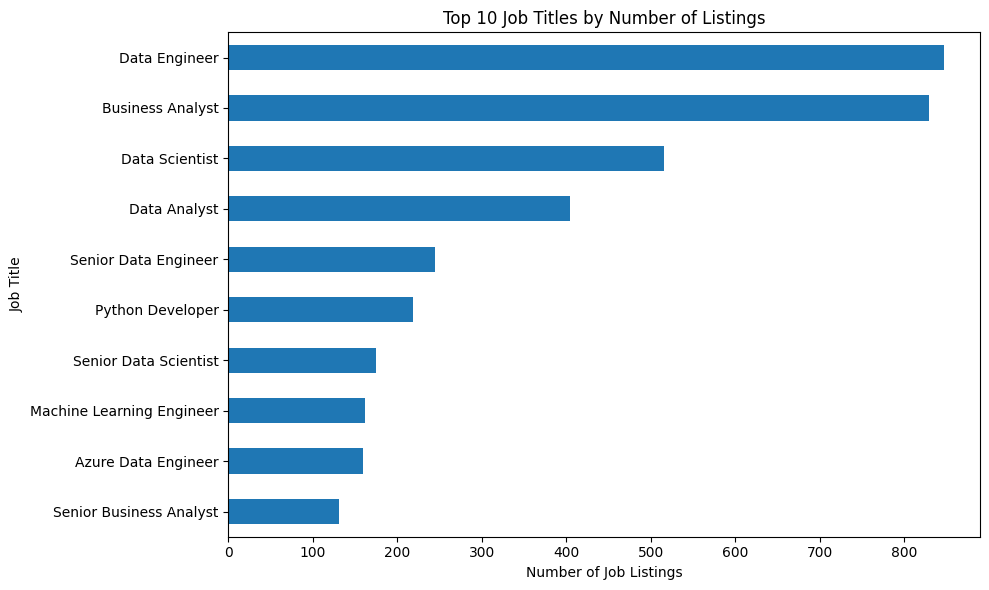

In [15]:

if "job_title" in df.columns:
    top_jobs = df["job_title"].value_counts().head(10)

    display(top_jobs.to_frame(name="Number of Job Listings"))

    top_jobs.sort_values().plot(
        kind="barh",
        figsize=(10, 6),
        title="Top 10 Job Titles by Number of Listings"
    )

    plt.xlabel("Number of Job Listings")
    plt.ylabel("Job Title")
    plt.tight_layout()
    plt.show()


,Number of Job Listings
company_name,
Tata Consultancy Services,653
Accenture,438
EY,340
Leading Client,243
Infosys,209
Capgemini,195
Photon,193
Logic Planet,185
Hexaware Technologies,147


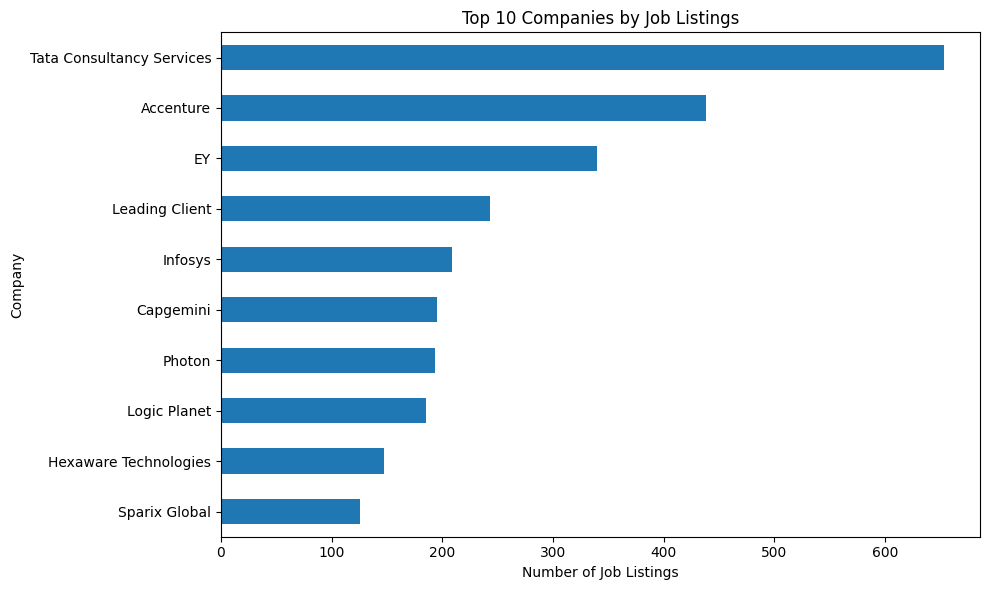

In [16]:

if "company_name" in df.columns:
    top_companies = df["company_name"].value_counts().head(10)

    display(top_companies.to_frame(name="Number of Job Listings"))

    top_companies.sort_values().plot(
        kind="barh",
        figsize=(10, 6),
        title="Top 10 Companies by Job Listings"
    )

    plt.xlabel("Number of Job Listings")
    plt.ylabel("Company")
    plt.tight_layout()
    plt.show()


## 9. Salary Analysis

This section examines salary information available in the dataset.

The analysis includes:

- Descriptive statistics for minimum, maximum, and midpoint salary.
- Identification of job titles with higher average salary midpoint.
- Comparison of salary statistics across experience tiers.

### Business Questions

1. Which listed job titles have higher average salary midpoint values?
2. How do salary figures vary across experience levels?
3. How many listings are included in each salary comparison?

### Data Quality Consideration

The current output contains zero values in the salary columns, and the median salary midpoint is zero. These values may affect the calculated averages and medians.

Before drawing conclusions, verify whether zero represents an undisclosed salary, a missing value, or a genuine value in the source dataset. Salary comparisons should be interpreted only after this issue is addressed.

In [17]:

# Identify salary-related columns
salary_columns = [
    col for col in df.columns
    if "salary" in col.lower() or "lpa" in col.lower()
]

print("Salary-related Columns:")
print(salary_columns)

display(df[salary_columns].head())


Salary-related Columns:
['salary_raw', 'salary_min_lpa', 'salary_max_lpa', 'salary_disclosed', 'salary_tier', 'salary_midpoint_lpa', 'salary_negotiable']


,salary_raw,salary_min_lpa,salary_max_lpa,salary_disclosed,salary_tier,salary_midpoint_lpa,salary_negotiable
0,Not Disclosed,0.0,0.0,No,Undisclosed,0.0,No
1,Not Disclosed,0.0,0.0,No,Undisclosed,0.0,No
2,Not Disclosed,0.0,0.0,No,Undisclosed,0.0,No
3,Not Disclosed,0.0,0.0,No,Undisclosed,0.0,No
4,Not Disclosed,0.0,0.0,No,Undisclosed,0.0,False


In [18]:

salary_cols = [
    "salary_min_lpa",
    "salary_max_lpa",
    "salary_midpoint_lpa"
]

available_cols = [col for col in salary_cols if col in df.columns]

if available_cols:
    salary_summary = df[available_cols].describe().T
    display(salary_summary)
else:
    print("Expected salary columns not found. Check salary_columns output.")


,count,mean,std,min,25%,50%,75%,max
salary_min_lpa,23201.0,1.383952,4.841570,0.0,0.0,0.0,0.0,85.0
salary_max_lpa,23201.0,2.271790,7.469383,0.0,0.0,0.0,0.0,90.0
salary_midpoint_lpa,23201.0,1.827872,6.109373,0.0,0.0,0.0,0.0,87.5


In [19]:

if "salary_midpoint_lpa" in df.columns and "job_title" in df.columns:

    salary_data = df.dropna(
        subset=["salary_midpoint_lpa", "job_title"]
    ).copy()

    salary_data = salary_data[
        salary_data["salary_midpoint_lpa"] > 0
    ]

    top_salary_roles = (
        salary_data.groupby("job_title")
        .agg(
            Average_Salary_LPA=("salary_midpoint_lpa", "mean"),
            Job_Listings=("salary_midpoint_lpa", "count")
        )
        .query("Job_Listings >= 3")
        .sort_values("Average_Salary_LPA", ascending=False)
        .head(10)
    )

    display(top_salary_roles.round(2))

else:
    print("Required salary_midpoint_lpa or job_title column not found.")


,Average_Salary_LPA,Job_Listings
job_title,,
AI/ Machine Learning Managers/ Architects/ SM/ AD/ AVP- Fortune 500,52.50,4
Senior AI/ML Engineer,36.67,3
Data Architect,34.12,4
Data Engineer with GCP,33.75,6
Data Modeller,33.44,4
Lead Aws Data Engineer-- US MNC (analytics),32.50,3
Lead Data Scientist,32.36,9
Artificial Intelligence Architect,31.79,7
AI/ Machine Learning Engineers/ Leads/ Architects/ Mngrs- Fortune 500,27.50,4


In [20]:

if "experience_tier" in df.columns and "salary_midpoint_lpa" in df.columns:

    experience_salary = (
        df.dropna(subset=["experience_tier", "salary_midpoint_lpa"])
        .groupby("experience_tier")
        .agg(
            Average_Salary=("salary_midpoint_lpa", "mean"),
            Median_Salary=("salary_midpoint_lpa", "median"),
            Job_Count=("salary_midpoint_lpa", "count")
        )
        .sort_values("Average_Salary", ascending=False)
    )

    display(experience_salary.round(2))

else:
    print("Required experience_tier or salary_midpoint_lpa column not found.")


,Average_Salary,Median_Salary,Job_Count
experience_tier,,,
Lead/Architect (9+ Yrs),3.61,0.0,1145
Senior (6-8 Yrs),3.08,0.0,4810
Mid (3-5 Yrs),1.85,0.0,10112
Fresher,1.03,0.0,2219
Junior (0-2 Yrs),0.51,0.0,4915


## 10. Skills Demand Analysis

This section explores skills mentioned in job listings.

### Overall Skills Analysis

The `skills_required` column is split into individual skill entries. The entries are then counted to identify the most frequently mentioned skills.

A horizontal bar chart displays the top 15 skill entries.

### Skills by Role Category

Skills are also grouped by `role_category` to identify frequently mentioned skills within each category.

### Business Purpose

This analysis can help job seekers identify skills that appear frequently in the dataset and understand how skill requirements differ across role categories.

**Data quality note:** Some skill entries differ only in capitalization, such as `Python` and `python`. These should be standardized before treating them as separate skills. Skill mentions indicate frequency in the available listings, not necessarily the importance or proficiency level required.

In [21]:

# Identify columns related to skills
skill_columns = [
    col for col in df.columns
    if "skill" in col.lower()
]

print("Skills-related columns:", skill_columns)

if skill_columns:
    display(df[skill_columns].head(10))


Skills-related columns: ['skills_required', 'skills_count', 'skill_domain']


,skills_required,skills_count,skill_domain
0,"Computer science, Data analysis, data science,...",8,Business Intelligence
1,"Basic, Data management, Business analytics, An...",8,AI/ML/DL
2,Not Available,0,Business Intelligence
3,Not Available,0,Data Science
4,Not Available,0,Data Science
5,Not Available,0,Data Science
6,Not Available,0,Data Science
7,"Supply chain, data science, Aerospace, Machine...",8,AI/ML/DL
8,"Product management, Prototype, data science, C...",8,AI/ML/DL
9,"python, data analysis, data domain, vertex, da...",8,AI/ML/DL


,Job Mentions
skills_required,
Python,2744
Data analysis,2360
Analytical,2345
SQL,2306
Automation,1935
Machine learning,1929
Artificial Intelligence,1835
Computer science,1687
Data,1615


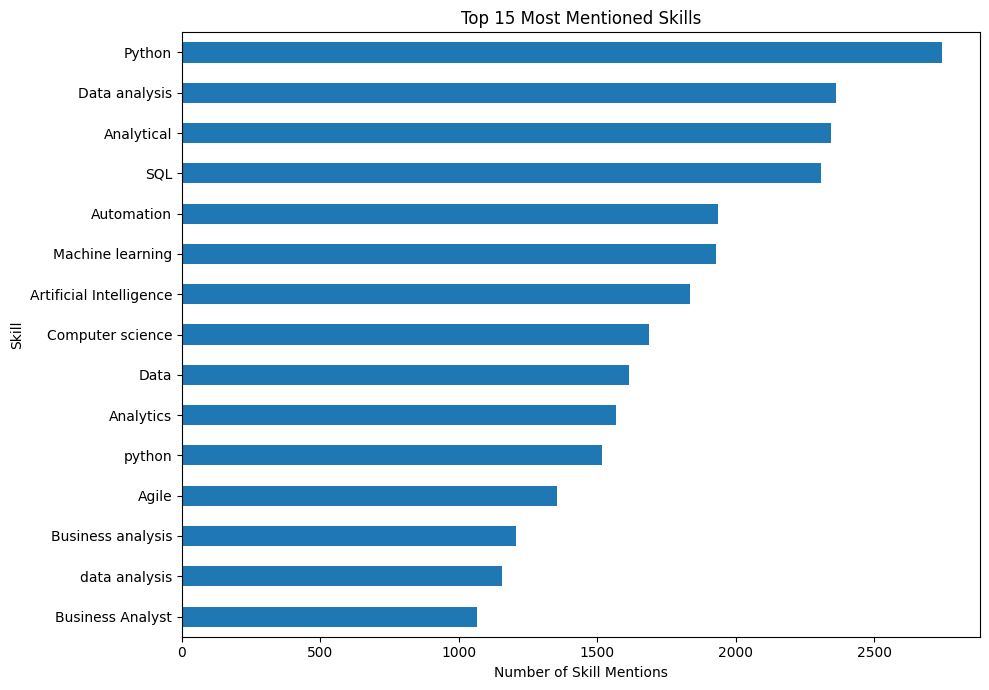

In [22]:

from collections import Counter

if "skills_required" in df.columns:

    skills_data = df["skills_required"].dropna()

    all_skills = skills_data.str.split(",").explode().str.strip()

    all_skills = all_skills[all_skills != ""]

    top_skills = all_skills.value_counts().head(15)

    display(top_skills.to_frame(name="Job Mentions"))

    top_skills.sort_values().plot(
        kind="barh",
        figsize=(10, 7),
        title="Top 15 Most Mentioned Skills"
    )

    plt.xlabel("Number of Skill Mentions")
    plt.ylabel("Skill")
    plt.tight_layout()
    plt.show()

else:
    print("skills_required column not found. Check skill_columns output.")


In [23]:

if "role_category" in df.columns and "skills_required" in df.columns:

    role_skills = df[
        ["role_category", "skills_required"]
    ].dropna().copy()

    role_skills["skills_required"] = (
        role_skills["skills_required"].str.split(",")
    )

    role_skills = role_skills.explode("skills_required")

    role_skills["skills_required"] = (
        role_skills["skills_required"].str.strip()
    )

    role_skills = role_skills[
        role_skills["skills_required"] != ""
    ]

    result = (
        role_skills.groupby(
            ["role_category", "skills_required"]
        ).size()
        .reset_index(name="Job Mentions")
        .sort_values(
            ["role_category", "Job Mentions"],
            ascending=[True, False]
        )
    )

    display(result.groupby("role_category").head(5))

else:
    print("Required columns are not available.")


,role_category,skills_required,Job Mentions
515,Business Analyst,Business analysis,861
448,Business Analyst,Business Analyst,793
4233,Business Analyst,business analysis,562
179,Business Analyst,Analytical,534
128,Business Analyst,Agile,442
6959,Data Analyst,Data analysis,1542
10622,Data Analyst,data analysis,822
6022,Data Analyst,Analytical,649
9326,Data Analyst,SQL,356
6032,Data Analyst,Analytics,321


## 11. Experience Level and Fresher Opportunities

This section examines job listings by experience tier and evaluates the distribution of fresher-friendly opportunities.

The analysis includes:

- Number of listings in each experience tier.
- Distribution of fresher-friendly and non-fresher-friendly listings.
- Average and median salary midpoint by experience tier.

### Business Questions

1. Which experience tier has the largest number of listings?
2. How many listings are classified as fresher-friendly?
3. How do salary statistics differ across experience tiers?

### Business Purpose

The findings can help entry-level candidates understand the number of opportunities represented in the dataset and compare them with roles requiring more experience.

Salary comparisons must be interpreted carefully until zero salary values are validated.

In [24]:

# Experience and Fresher Opportunity Analysis

if "is_fresher_friendly" in df.columns:
    print("Fresher-Friendly Job Distribution:")
    display(
        df["is_fresher_friendly"]
        .value_counts(dropna=False)
        .to_frame("Job Listings")
    )

if "experience_tier" in df.columns:
    print("\nJobs by Experience Level:")
    display(
        df["experience_tier"]
        .value_counts(dropna=False)
        .to_frame("Job Listings")
    )

if "experience_tier" in df.columns and "salary_midpoint_lpa" in df.columns:
    experience_analysis = (
        df.dropna(subset=["experience_tier", "salary_midpoint_lpa"])
        .groupby("experience_tier")
        .agg(
            Average_Salary_LPA=("salary_midpoint_lpa", "mean"),
            Median_Salary_LPA=("salary_midpoint_lpa", "median"),
            Job_Listings=("salary_midpoint_lpa", "count")
        )
        .round(2)
        .sort_values("Average_Salary_LPA", ascending=False)
    )

    print("\nSalary by Experience Level:")
    display(experience_analysis)


Fresher-Friendly Job Distribution:


,Job Listings
is_fresher_friendly,
False,19019
True,4182



Jobs by Experience Level:


,Job Listings
experience_tier,
Mid (3-5 Yrs),10112
Junior (0-2 Yrs),4915
Senior (6-8 Yrs),4810
Fresher,2219
Lead/Architect (9+ Yrs),1145



Salary by Experience Level:


,Average_Salary_LPA,Median_Salary_LPA,Job_Listings
experience_tier,,,
Lead/Architect (9+ Yrs),3.61,0.0,1145
Senior (6-8 Yrs),3.08,0.0,4810
Mid (3-5 Yrs),1.85,0.0,10112
Fresher,1.03,0.0,2219
Junior (0-2 Yrs),0.51,0.0,4915


## 12. Hiring Location and Work Mode Analysis

This section explores where job listings are concentrated and how they are distributed across work arrangements.

### Location Analysis

The top 10 cities are ranked by the number of job listings. A horizontal bar chart is used to compare the locations.

### Work Mode Analysis

Listings are grouped into the available work modes: On-site, Hybrid, and Remote.

### Initial Findings

The top five cities by listing count are Mumbai, Bangalore, Chennai, Pune, and Noida.

The dataset contains 18,701 On-site listings, 2,347 Hybrid listings, and 2,153 Remote listings.

### Business Purpose

This analysis helps job seekers explore locations with more listings and understand the distribution of work arrangements in the dataset.

These results describe the available dataset and should not automatically be treated as a complete representation of the Indian technology job market.

,Job Listings
primary_city,
Mumbai,3276
Bangalore,2830
Chennai,2666
Pune,2606
Noida,2585
Gurgaon,2210
Remote,2010
Kolkata,1735
Ahmedabad,1352


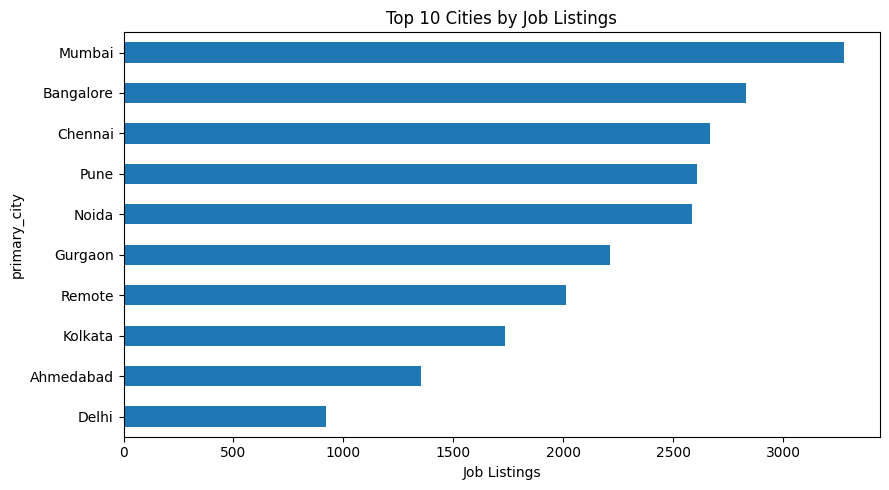

,Job Listings
work_mode,
On-site,18701
Hybrid,2347
Remote,2153


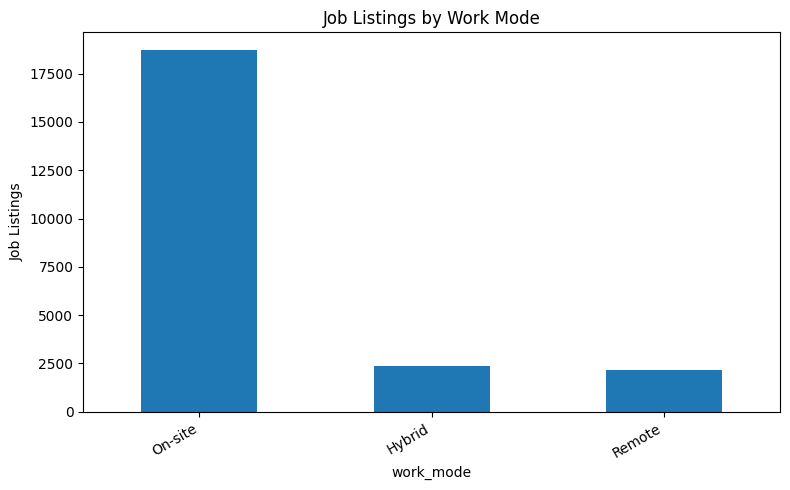

In [25]:

# Top 10 cities by job listings
if "primary_city" in df.columns:
    city_jobs = df["primary_city"].value_counts().head(10)

    display(city_jobs.to_frame("Job Listings"))

    city_jobs.sort_values().plot(
        kind="barh",
        figsize=(9, 5),
        title="Top 10 Cities by Job Listings"
    )
    plt.xlabel("Job Listings")
    plt.tight_layout()
    plt.show()

# Work mode distribution
if "work_mode" in df.columns:
    work_mode_jobs = df["work_mode"].value_counts(dropna=False)

    display(work_mode_jobs.to_frame("Job Listings"))

    work_mode_jobs.dropna().plot(
        kind="bar",
        figsize=(8, 5),
        title="Job Listings by Work Mode"
    )
    plt.ylabel("Job Listings")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


## 13. Key Business Insights

The exploratory analysis provides an overview of job listings, role categories, hiring locations, work modes, salary fields, and required skills.

The current results indicate that:

- The dataset contains 23,201 job listings across 6,991 unique companies and 198 cities.
- Data Scientist and Data Analyst are among the most represented role categories.
- Mumbai, Bangalore, Chennai, Pune, and Noida have the highest listing counts among the cities shown.
- On-site listings account for the largest number of records among the three work modes.
- Python, Data analysis, Analytical, and SQL are among the most frequently recorded skill entries.

Salary conclusions require further validation because zero values affect the salary summary. Skill counts should also be standardized for capitalization before final interpretation.

## 14. Recommendations

Based on the patterns observed in this dataset:

1. Job seekers can review frequently listed role categories when exploring career options.
2. Candidates can investigate recurring skills such as Python, SQL, and data analysis as part of their learning plans.
3. Candidates can compare opportunities across the cities represented in the dataset.
4. Job seekers should evaluate work mode, experience requirements, and salary information together rather than relying on a single metric.
5. Salary data and skill labels should be validated before final reporting.

## 15. Conclusion

This project uses Python-based exploratory data analysis to examine the Indian Tech Jobs 2026 dataset. It summarizes job listings by role, company, location, work mode, skills, and experience level.

The analysis provides a foundation for further SQL-based business analysis and an interactive Power BI dashboard. Before finalizing salary-related conclusions, the meaning of zero salary values should be verified and handled appropriately.

In [31]:

# Final project summary

print("INDIAN TECH JOBS 2026 - BUSINESS SUMMARY")
print("-" * 45)

print("Total Job Listings:", len(df))

if "company_name" in df.columns:
    print("Unique Companies:", df["company_name"].nunique())

if "primary_city" in df.columns:
    print("Unique Cities:", df["primary_city"].nunique())

if "work_mode" in df.columns:
    print("\nWork Mode Distribution:")
    print(df["work_mode"].value_counts().head())

if "role_category" in df.columns:
    print("\nTop Job Categories:")
    print(df["role_category"].value_counts().head(5))

if "primary_city" in df.columns:
    print("\nTop Hiring Cities:")
    print(df["primary_city"].value_counts().head(5))


INDIAN TECH JOBS 2026 - BUSINESS SUMMARY
---------------------------------------------
Total Job Listings: 23201
Unique Companies: 6991
Unique Cities: 198

Work Mode Distribution:
work_mode
On-site    18701
Hybrid      2347
Remote      2153
Name: count, dtype: int64

Top Job Categories:
role_category
Data Scientist               6455
Data Analyst                 4729
Business Analyst             4505
Machine Learning Engineer    4004
Data Engineer                1922
Name: count, dtype: int64

Top Hiring Cities:
primary_city
Mumbai       3276
Bangalore    2830
Chennai      2666
Pune         2606
Noida        2585
Name: count, dtype: int64


In [10]:
print("=" * 55)
print("INDIAN TECH JOBS 2026 - FINAL BUSINESS INSIGHTS")
print("=" * 55)

if "primary_city" in df.columns:
    print("\n1. Top Hiring Cities")
    display(df["primary_city"].value_counts().head(5))

if "role_category" in df.columns:
    print("\n2. Most In-Demand Job Categories")
    display(df["role_category"].value_counts().head(5))

if "work_mode" in df.columns:
    print("\n3. Work Mode Distribution")
    display(df["work_mode"].value_counts())

if "skills_required" in df.columns:
    print("\n4. Most Frequently Mentioned Skills")
    skills = (
        df["skills_required"]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )
    display(skills[skills.ne("")].value_counts().head(10))

if "salary_midpoint_lpa" in df.columns:
    print("\n5. Overall Salary Overview")
    display(
        df["salary_midpoint_lpa"]
        .describe()
        .round(2)
        .to_frame("Salary in LPA")
    )

INDIAN TECH JOBS 2026 - FINAL BUSINESS INSIGHTS

1. Top Hiring Cities


primary_city
Mumbai       3276
Bangalore    2830
Chennai      2666
Pune         2606
Noida        2585
Name: count, dtype: int64


2. Most In-Demand Job Categories


role_category
Data Scientist               6455
Data Analyst                 4729
Business Analyst             4505
Machine Learning Engineer    4004
Data Engineer                1922
Name: count, dtype: int64


3. Work Mode Distribution


work_mode
On-site    18701
Hybrid      2347
Remote      2153
Name: count, dtype: int64


4. Most Frequently Mentioned Skills


skills_required
Python                     2744
Data analysis              2360
Analytical                 2345
SQL                        2306
Automation                 1935
Machine learning           1929
Artificial Intelligence    1835
Computer science           1687
Data                       1615
Analytics                  1567
Name: count, dtype: int64


5. Overall Salary Overview


,Salary in LPA
count,23201.00
mean,1.83
std,6.11
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,87.50


In [11]:
print("=" * 50)
print("INDIAN TECH JOBS 2026 - BUSINESS INSIGHTS")
print("=" * 50)

# 1. Top Hiring Cities
if "primary_city" in df.columns:
    print("\n1. Top 5 Hiring Cities")
    display(df["primary_city"].value_counts().head(5))

# 2. Popular Job Categories
if "role_category" in df.columns:
    print("\n2. Top 5 Job Categories")
    display(df["role_category"].value_counts().head(5))

# 3. Work Mode Distribution
if "work_mode" in df.columns:
    print("\n3. Work Mode Distribution")
    display(df["work_mode"].value_counts())

# 4. Most Demanded Skills
if "skills_required" in df.columns:
    skills = (
        df["skills_required"]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )
    print("\n4. Top 10 Skills")
    display(skills[skills.ne("")].value_counts().head(10))

# 5. Salary Overview
if "salary_midpoint_lpa" in df.columns:
    print("\n5. Salary Overview (LPA)")
    display(df["salary_midpoint_lpa"].describe().round(2))

INDIAN TECH JOBS 2026 - BUSINESS INSIGHTS

1. Top 5 Hiring Cities


primary_city
Mumbai       3276
Bangalore    2830
Chennai      2666
Pune         2606
Noida        2585
Name: count, dtype: int64


2. Top 5 Job Categories


role_category
Data Scientist               6455
Data Analyst                 4729
Business Analyst             4505
Machine Learning Engineer    4004
Data Engineer                1922
Name: count, dtype: int64


3. Work Mode Distribution


work_mode
On-site    18701
Hybrid      2347
Remote      2153
Name: count, dtype: int64


4. Top 10 Skills


skills_required
Python                     2744
Data analysis              2360
Analytical                 2345
SQL                        2306
Automation                 1935
Machine learning           1929
Artificial Intelligence    1835
Computer science           1687
Data                       1615
Analytics                  1567
Name: count, dtype: int64


5. Salary Overview (LPA)


count    23201.00
mean         1.83
std          6.11
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         87.50
Name: salary_midpoint_lpa, dtype: float64